In [2]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU: Not available")

PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [4]:
from google.colab import drive

drive.mount('/content/drive')

ValueError: Mountpoint must not already contain files

In [5]:
import os

drive_path = "/content/drive/MyDrive"

print(os.listdir(drive_path)[:20])

['sign-language-interpreter']


In [11]:
import os

zip_path = "/content/drive/MyDrive/sign-language-interpreter/archive.zip"

print("ZIP exists:", os.path.exists(zip_path))

if os.path.exists(zip_path):
    print(f"ZIP size: {os.path.getsize(zip_path) / (1024**3):.2f} GB")

ZIP exists: True
ZIP size: 1.03 GB


In [10]:
import os
import shutil

from google.colab import drive

# Check whether Drive is already mounted
if os.path.ismount("/content/drive"):
    print("Google Drive is already mounted.")
else:
    print("Drive is not mounted. Cleaning the mount point...")

    # Remove leftover mount-point directory if it exists
    if os.path.exists("/content/drive"):
        shutil.rmtree("/content/drive")

    os.makedirs("/content/drive", exist_ok=True)

    drive.mount("/content/drive")

Drive is not mounted. Cleaning the mount point...
Mounted at /content/drive


In [12]:
import os
import zipfile

zip_path = "/content/drive/MyDrive/sign-language-interpreter/archive.zip"
extract_path = "/content/asl_dataset"

os.makedirs(extract_path, exist_ok=True)

print("Extracting dataset...")
print("This may take a few minutes.")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("\nExtraction complete!")

Extracting dataset...
This may take a few minutes.

Extraction complete!


In [13]:
import os

print("Extracted folders:")

for item in os.listdir("/content/asl_dataset"):
    print(" -", item)

Extracted folders:
 - asl_alphabet_test
 - asl_alphabet_train


In [14]:
train_path = "/content/asl_dataset/asl_alphabet_train/asl_alphabet_train"

classes = sorted([
    folder
    for folder in os.listdir(train_path)
    if os.path.isdir(os.path.join(train_path, folder))
])

print("\nNumber of classes:", len(classes))
print("Classes:", classes)


Number of classes: 29
Classes: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']


In [15]:
import os
import pandas as pd

from sklearn.model_selection import train_test_split


# ==========================================
# Dataset path
# ==========================================

DATASET_PATH = "/content/asl_dataset/asl_alphabet_train/asl_alphabet_train"


# ==========================================
# Get classes
# ==========================================

classes = sorted([
    folder
    for folder in os.listdir(DATASET_PATH)
    if os.path.isdir(
        os.path.join(DATASET_PATH, folder)
    )
])

class_to_index = {
    class_name: index
    for index, class_name in enumerate(classes)
}


print("Number of classes:", len(classes))

print("\nClass mapping:")
for class_name, index in class_to_index.items():
    print(f"{index:2d} -> {class_name}")


# ==========================================
# Collect image paths
# ==========================================

records = []

for class_name in classes:

    class_path = os.path.join(
        DATASET_PATH,
        class_name
    )

    for filename in os.listdir(class_path):

        if filename.lower().endswith(
            (".jpg", ".jpeg", ".png")
        ):

            records.append({
                "image_path": os.path.join(
                    class_path,
                    filename
                ),
                "label": class_name,
                "label_id": class_to_index[class_name]
            })


df = pd.DataFrame(records)

print("\nTotal images:", len(df))


# ==========================================
# 70% Train / 30% Temporary
# ==========================================

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=42
)


# ==========================================
# 15% Validation / 15% Test
# ==========================================

validation_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)


# ==========================================
# Save manifests
# ==========================================

os.makedirs(
    "/content/asl_manifests",
    exist_ok=True
)

train_df.to_csv(
    "/content/asl_manifests/train.csv",
    index=False
)

validation_df.to_csv(
    "/content/asl_manifests/validation.csv",
    index=False
)

test_df.to_csv(
    "/content/asl_manifests/test.csv",
    index=False
)


# ==========================================
# Results
# ==========================================

print("\n" + "=" * 50)
print("DATA SPLIT")
print("=" * 50)

print(f"Training:   {len(train_df):,}")
print(f"Validation: {len(validation_df):,}")
print(f"Testing:    {len(test_df):,}")

print("\nSplit files saved successfully.")

Number of classes: 29

Class mapping:
 0 -> A
 1 -> B
 2 -> C
 3 -> D
 4 -> E
 5 -> F
 6 -> G
 7 -> H
 8 -> I
 9 -> J
10 -> K
11 -> L
12 -> M
13 -> N
14 -> O
15 -> P
16 -> Q
17 -> R
18 -> S
19 -> T
20 -> U
21 -> V
22 -> W
23 -> X
24 -> Y
25 -> Z
26 -> del
27 -> nothing
28 -> space

Total images: 87000

DATA SPLIT
Training:   60,900
Validation: 13,050
Testing:    13,050

Split files saved successfully.


In [16]:
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [17]:
import pandas as pd
import torch

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms


# ============================================================
# Device
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0))


# ============================================================
# Dataset class
# ============================================================

class ASLDataset(Dataset):

    def __init__(self, csv_file):

        self.data = pd.read_csv(csv_file)

        self.transform = transforms.Compose([
            transforms.Resize((64, 64)),
            transforms.ToTensor(),
            transforms.Normalize(
                mean=[0.5, 0.5, 0.5],
                std=[0.5, 0.5, 0.5]
            )
        ])

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):

        image_path = self.data.iloc[index]["image_path"]
        label = int(self.data.iloc[index]["label_id"])

        image = Image.open(
            image_path
        ).convert("RGB")

        image = self.transform(image)

        return image, torch.tensor(
            label,
            dtype=torch.long
        )


# ============================================================
# Create datasets
# ============================================================

train_dataset = ASLDataset(
    "/content/asl_manifests/train.csv"
)

validation_dataset = ASLDataset(
    "/content/asl_manifests/validation.csv"
)

test_dataset = ASLDataset(
    "/content/asl_manifests/test.csv"
)


# ============================================================
# DataLoaders
# ============================================================

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


# ============================================================
# Test one batch
# ============================================================

images, labels = next(iter(train_loader))

images = images.to(
    device,
    non_blocking=True
)

labels = labels.to(
    device,
    non_blocking=True
)


print("\n" + "=" * 60)
print("GPU DATA PIPELINE TEST")
print("=" * 60)

print("Training images:", len(train_dataset))
print("Validation images:", len(validation_dataset))
print("Testing images:", len(test_dataset))

print("\nBatch image shape:", images.shape)
print("Batch label shape:", labels.shape)

print("Image device:", images.device)
print("Label device:", labels.device)

print("\nData pipeline test successful!")

Device: cuda
GPU: Tesla T4

GPU DATA PIPELINE TEST
Training images: 60900
Validation images: 13050
Testing images: 13050

Batch image shape: torch.Size([64, 3, 64, 64])
Batch label shape: torch.Size([64])
Image device: cuda:0
Label device: cuda:0

Data pipeline test successful!


In [18]:
import torch
import torch.nn as nn


class ASLCNN(nn.Module):

    def __init__(self, num_classes=29):

        super().__init__()

        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(
                3, 32,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 2
            nn.Conv2d(
                32, 64,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 3
            nn.Conv2d(
                64, 128,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Dropout(0.25)
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(
                128 * 8 * 8,
                256
            ),

            nn.ReLU(),

            nn.Dropout(0.5),

            nn.Linear(
                256,
                num_classes
            )
        )

    def forward(self, x):

        x = self.features(x)

        x = self.classifier(x)

        return x


# Create model
model = ASLCNN(
    num_classes=29
).to(device)


print(model)
dummy = torch.randn(
    64, 3, 64, 64
).to(device)

output = model(dummy)

print("\nInput:", dummy.shape)
print("Output:", output.shape)

ASLCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Dropout(p=0.25, inplace=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=8192, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=256, out_features=29, bias=True)
  )
)

Input: torch.Size([64, 3, 64, 64])
Output: torch.Size([64, 29])


In [19]:
import time
import os
import torch
import torch.nn as nn
import matplotlib.pyplot as plt


# ============================================================
# Training configuration
# ============================================================

EPOCHS = 10
LEARNING_RATE = 0.001

MODEL_DIR = "/content/asl_models"
os.makedirs(MODEL_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "asl_cnn_best.pth"
)


# ============================================================
# Loss and optimizer
# ============================================================

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)


# ============================================================
# History
# ============================================================

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

best_val_accuracy = 0.0


# ============================================================
# Training loop
# ============================================================

print("=" * 70)
print("STARTING FULL CNN TRAINING")
print("=" * 70)

print(f"Device: {device}")
print(f"Epochs: {EPOCHS}")
print(f"Training images: {len(train_dataset):,}")
print(f"Validation images: {len(validation_dataset):,}")
print(f"Batch size: 64")
print("=" * 70)


for epoch in range(EPOCHS):

    start_time = time.time()

    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for batch_index, (images, labels) in enumerate(train_loader):

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        # Clear gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(
            outputs,
            labels
        )

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Statistics
        running_loss += (
            loss.item() * images.size(0)
        )

        _, predicted = torch.max(
            outputs,
            1
        )

        total += labels.size(0)

        correct += (
            predicted == labels
        ).sum().item()


    train_loss = running_loss / total

    train_accuracy = (
        100.0 * correct / total
    )


    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    model.eval()

    validation_loss = 0.0

    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in validation_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            validation_loss += (
                loss.item() * images.size(0)
            )

            _, predicted = torch.max(
                outputs,
                1
            )

            val_total += labels.size(0)

            val_correct += (
                predicted == labels
            ).sum().item()


    val_loss = (
        validation_loss / val_total
    )

    val_accuracy = (
        100.0 * val_correct / val_total
    )


    # --------------------------------------------------------
    # Store history
    # --------------------------------------------------------

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)


    # --------------------------------------------------------
    # Save best model
    # --------------------------------------------------------

    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "class_to_index": class_to_index,
                "val_accuracy": val_accuracy,
                "epoch": epoch + 1
            },
            BEST_MODEL_PATH
        )

        saved_message = " ← BEST MODEL SAVED"

    else:

        saved_message = ""


    # --------------------------------------------------------
    # Epoch results
    # --------------------------------------------------------

    elapsed = time.time() - start_time

    print(
        f"\nEpoch [{epoch + 1}/{EPOCHS}]"
    )

    print(
        f"Train Loss: {train_loss:.4f}"
    )

    print(
        f"Train Accuracy: {train_accuracy:.2f}%"
    )

    print(
        f"Val Loss: {val_loss:.4f}"
    )

    print(
        f"Val Accuracy: {val_accuracy:.2f}%"
    )

    print(
        f"Time: {elapsed:.1f} seconds"
        f"{saved_message}"
    )


print("\n" + "=" * 70)
print("TRAINING COMPLETE")
print("=" * 70)

print(
    f"Best validation accuracy: "
    f"{best_val_accuracy:.2f}%"
)

print(
    f"Best model saved to:\n{BEST_MODEL_PATH}"
)

STARTING FULL CNN TRAINING
Device: cuda
Epochs: 10
Training images: 60,900
Validation images: 13,050
Batch size: 64

Epoch [1/10]
Train Loss: 1.3064
Train Accuracy: 57.85%
Val Loss: 0.3004
Val Accuracy: 91.43%
Time: 87.1 seconds ← BEST MODEL SAVED

Epoch [2/10]
Train Loss: 0.3982
Train Accuracy: 85.94%
Val Loss: 0.1048
Val Accuracy: 97.09%
Time: 86.2 seconds ← BEST MODEL SAVED

Epoch [3/10]
Train Loss: 0.2394
Train Accuracy: 91.44%
Val Loss: 0.0501
Val Accuracy: 98.60%
Time: 85.6 seconds ← BEST MODEL SAVED

Epoch [4/10]
Train Loss: 0.1751
Train Accuracy: 93.87%
Val Loss: 0.0539
Val Accuracy: 98.37%
Time: 86.5 seconds

Epoch [5/10]
Train Loss: 0.1387
Train Accuracy: 95.13%
Val Loss: 0.0163
Val Accuracy: 99.62%
Time: 86.9 seconds ← BEST MODEL SAVED

Epoch [6/10]
Train Loss: 0.1141
Train Accuracy: 95.94%
Val Loss: 0.0133
Val Accuracy: 99.59%
Time: 87.4 seconds

Epoch [7/10]
Train Loss: 0.1027
Train Accuracy: 96.48%
Val Loss: 0.0072
Val Accuracy: 99.87%
Time: 87.7 seconds ← BEST MODEL SAVE

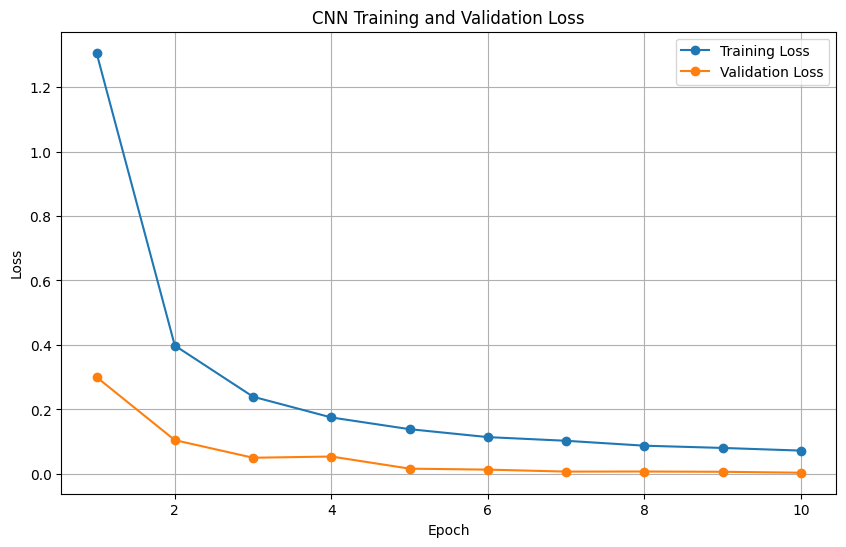

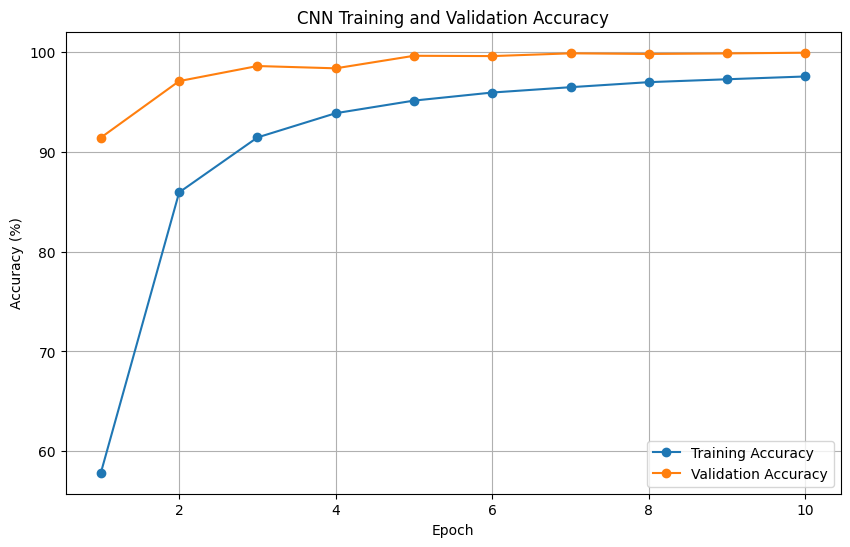

In [20]:
import matplotlib.pyplot as plt
import os

os.makedirs("/content/asl_results", exist_ok=True)

epochs_range = range(1, EPOCHS + 1)

# -----------------------------
# Loss curve
# -----------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    epochs_range,
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs_range,
    val_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training and Validation Loss")

plt.legend()
plt.grid(True)

plt.savefig(
    "/content/asl_results/cnn_loss_curve.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# -----------------------------
# Accuracy curve
# -----------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    epochs_range,
    train_accuracies,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    val_accuracies,
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("CNN Training and Validation Accuracy")

plt.legend()
plt.grid(True)

plt.savefig(
    "/content/asl_results/cnn_accuracy_curve.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [21]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

import numpy as np
import torch


# ============================================================
# Load best model
# ============================================================

checkpoint = torch.load(
    "/content/asl_models/asl_cnn_best.pth",
    map_location=device
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.to(device)

model.eval()


# ============================================================
# Test prediction
# ============================================================

all_predictions = []
all_labels = []


with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        outputs = model(images)

        _, predictions = torch.max(
            outputs,
            1
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )


# ============================================================
# Accuracy
# ============================================================

test_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

print("=" * 60)
print("CNN TEST RESULTS")
print("=" * 60)

print(
    f"Test Accuracy: "
    f"{test_accuracy * 100:.2f}%"
)


# ============================================================
# Classification report
# ============================================================

target_names = [
    class_name
    for class_name, index
    in sorted(
        class_to_index.items(),
        key=lambda x: x[1]
    )
]

report = classification_report(
    all_labels,
    all_predictions,
    target_names=target_names,
    digits=4
)

print("\nCLASSIFICATION REPORT")
print("=" * 60)
print(report)

CNN TEST RESULTS
Test Accuracy: 99.95%

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           A     1.0000    1.0000    1.0000       450
           B     1.0000    1.0000    1.0000       450
           C     1.0000    1.0000    1.0000       450
           D     1.0000    1.0000    1.0000       450
           E     1.0000    1.0000    1.0000       450
           F     1.0000    1.0000    1.0000       450
           G     1.0000    1.0000    1.0000       450
           H     1.0000    1.0000    1.0000       450
           I     0.9956    1.0000    0.9978       450
           J     1.0000    1.0000    1.0000       450
           K     1.0000    1.0000    1.0000       450
           L     1.0000    1.0000    1.0000       450
           M     1.0000    1.0000    1.0000       450
           N     1.0000    1.0000    1.0000       450
           O     1.0000    1.0000    1.0000       450
           P     1.0000    1.0000    1.0000       450
           Q     1.

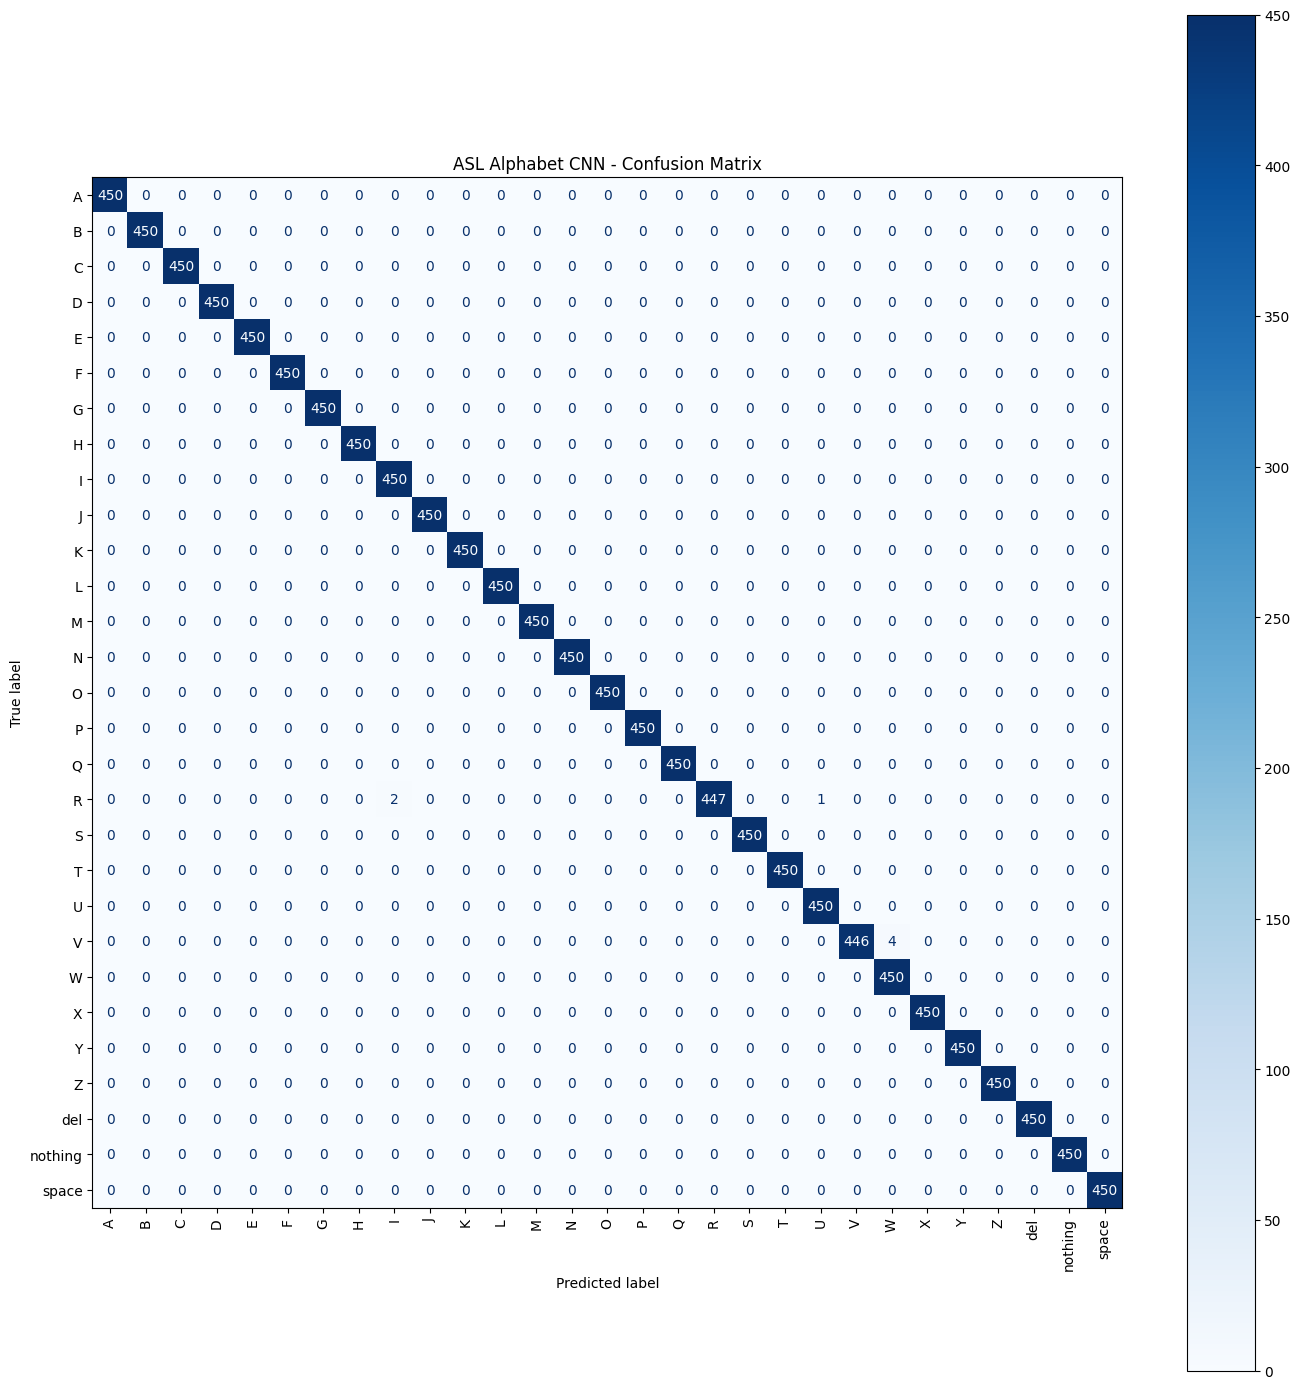

In [22]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Create confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions
)

fig, ax = plt.subplots(figsize=(14, 14))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=target_names
)

disp.plot(
    ax=ax,
    xticks_rotation=90,
    cmap="Blues",
    colorbar=True
)

plt.title(
    "ASL Alphabet CNN - Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    "/content/asl_results/cnn_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [23]:
import os
import shutil

# Create permanent project folders in Google Drive
drive_project = "/content/drive/MyDrive/sign-language-interpreter"

model_drive = os.path.join(
    drive_project,
    "models"
)

results_drive = os.path.join(
    drive_project,
    "results"
)

os.makedirs(model_drive, exist_ok=True)
os.makedirs(results_drive, exist_ok=True)


# Copy trained model
shutil.copy2(
    "/content/asl_models/asl_cnn_best.pth",
    os.path.join(
        model_drive,
        "asl_cnn_best.pth"
    )
)


# Copy result files
for filename in [
    "cnn_loss_curve.png",
    "cnn_accuracy_curve.png",
    "cnn_confusion_matrix.png"
]:

    source = os.path.join(
        "/content/asl_results",
        filename
    )

    if os.path.exists(source):

        shutil.copy2(
            source,
            os.path.join(
                results_drive,
                filename
            )
        )


print("Files saved to Google Drive!")
print("\nModel:")
print(os.path.join(
    model_drive,
    "asl_cnn_best.pth"
))

print("\nResults:")
print(results_drive)

Files saved to Google Drive!

Model:
/content/drive/MyDrive/sign-language-interpreter/models/asl_cnn_best.pth

Results:
/content/drive/MyDrive/sign-language-interpreter/results


In [24]:
from google.colab import files

files.download(
    "/content/asl_models/asl_cnn_best.pth"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>